100%|██████████| 16.0k/16.0k [00:00<00:00, 17.1MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/gokulrajkmv/unemployment-in-india/versions/5

--- First 5 Rows of the Dataset ---
           Region         Date Frequency  Estimated Unemployment Rate (%)  \
0  Andhra Pradesh   31-05-2019   Monthly                             3.65   
1  Andhra Pradesh   30-06-2019   Monthly                             3.05   
2  Andhra Pradesh   31-07-2019   Monthly                             3.75   
3  Andhra Pradesh   31-08-2019   Monthly                             3.32   
4  Andhra Pradesh   30-09-2019   Monthly                             5.17   

   Estimated Employed  Estimated Labour Participation Rate (%)   Area  
0          11999139.0                                    43.24  Rural  
1          11755881.0                                    42.05  Rural  
2          12086707.0                                    43.50  Rural  
3          12285693.0                                    43.97  Rural  
4          12256762.

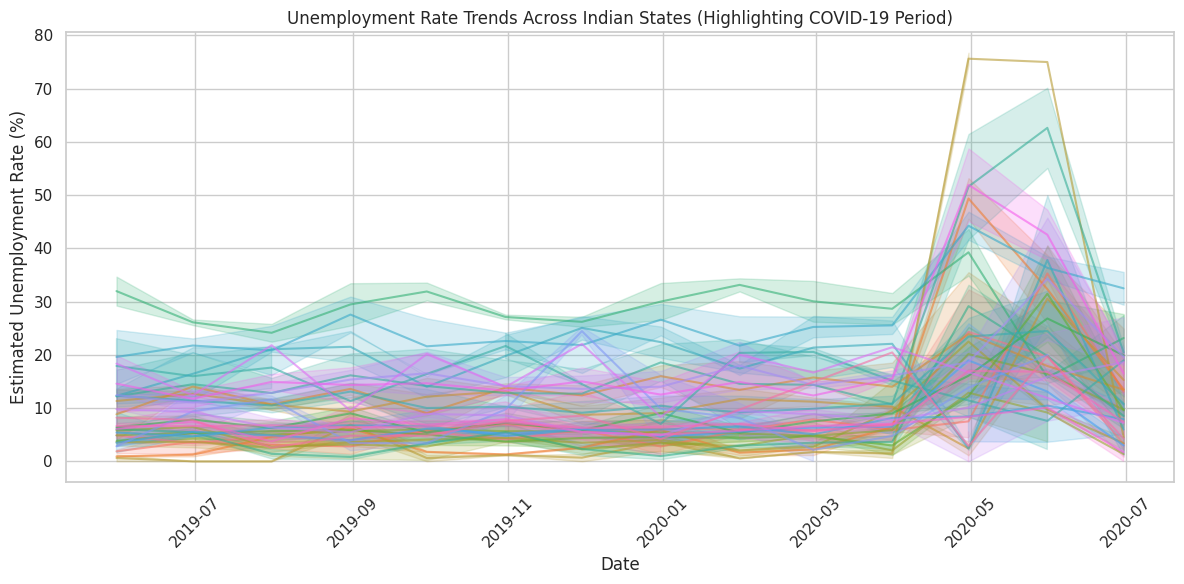

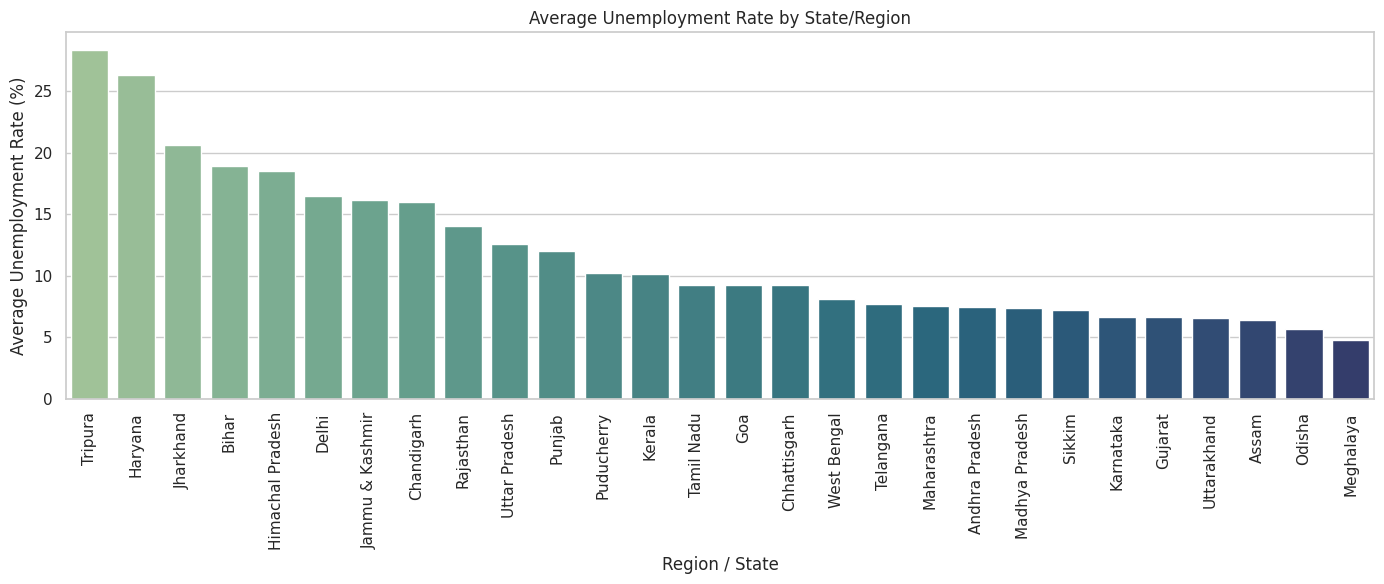


Task 2 Execution Completed Successfully!


In [2]:
!pip install kagglehub -q

import kagglehub
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress warnings for clean output
import warnings
warnings.filterwarnings('ignore')

print("Downloading Unemployment dataset from Kaggle...")
# 1. Download dataset using kagglehub
path = kagglehub.dataset_download("gokulrajkmv/unemployment-in-india")
print("Path to dataset files:", path)

# 2. Locate and load the CSV file into Pandas
files = os.listdir(path)
csv_file_name = [f for f in files if f.endswith('.csv')][0]
csv_file_path = os.path.join(path, csv_file_name)

df = pd.read_csv(csv_file_path)

# Clean column names (strip any leading/trailing whitespace)
df.columns = df.columns.str.strip()

print("\n--- First 5 Rows of the Dataset ---")
print(df.head())

print("\n--- Dataset Info ---")
print(df.info())

# 3. Data Cleaning
# Drop rows with missing values
df = df.dropna()

# Convert Date column to datetime objects
df['Date'] = pd.to_datetime(df['Date'].str.strip(), dayfirst=True)

# Sort data chronologically by date
df = df.sort_values('Date')

# 4. Data Exploration & Summary Statistics
print("\n--- Summary Statistics ---")
print(df.describe())

# 5. Data Visualization & Trend Analysis
# Setting up visual style
sns.set_theme(style="whitegrid")

# Plot 1: Unemployment Rate Trends Over Time Across Regions
plt.figure(figsize=(12, 6))
sns.lineplot(data=df, x='Date', y='Estimated Unemployment Rate (%)', hue='Region', legend=False, alpha=0.6)
plt.title('Unemployment Rate Trends Across Indian States (Highlighting COVID-19 Period)')
plt.xlabel('Date')
plt.ylabel('Estimated Unemployment Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Plot 2: Average Unemployment Rate by Region / State
plt.figure(figsize=(14, 6))
state_unemp = df.groupby('Region')['Estimated Unemployment Rate (%)'].mean().sort_values(ascending=False).reset_index()
sns.barplot(data=state_unemp, x='Region', y='Estimated Unemployment Rate (%)', palette='crest')
plt.title('Average Unemployment Rate by State/Region')
plt.xlabel('Region / State')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

print("\nTask 2 Execution Completed Successfully!")